# Frequency-search results explorer

Look at the output of an adversarial frequency search (`freq_search.py`): the
per-`(letter, pattern)` multipliers, the resulting per-word frequencies, and the
greedy strategy analyzed the *same way* as in `strategy_explorer` but under the
adversarial weighting (greedy playing against the adversarial word choices).

Generate a run first with e.g. `python math/freq_search.py 5` (saves to
`math/data/freq_search/len05.csv`); this notebook loads it back.

In [45]:
from pathlib import Path
import sys

def find_math_dir():
    cwd = Path.cwd().resolve()
    for c in (cwd, cwd.parent, cwd.parent.parent, cwd / 'math', cwd.parent / 'math'):
        if (c / 'freq_search.py').exists():
            return c
    raise FileNotFoundError('Could not find freq_search.py. Open from the repo root, math/, or math/notebooks/.')

math_dir = find_math_dir()
if str(math_dir) not in sys.path:
    sys.path.insert(0, str(math_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import freq_search, strategy

print(f'imported from {math_dir}')

imported from /Users/patrickliscio/My Documents/Pycharm Projects/Ballpark-Figures/hangman/math


## Load a search result

Loads the saved CSV for this length if present; otherwise runs one inline (which
can be slow for larger lengths).

In [81]:
LENGTH = 5

csv_path = math_dir / 'data' / 'freq_search' / f'len{LENGTH:02d}.csv'
if csv_path.exists():
    s = freq_search.FrequencySearch.reconstruct(LENGTH, csv_path)
    print(f'loaded saved run: {csv_path.name}')
else:
    print(f'no saved run at {csv_path}\nrunning one inline (may take a while)...')
    s = freq_search.FrequencySearch(LENGTH)
    s.run(verbose=False)

game, f = s.game, s.freq
print(f'length {LENGTH}: {game.N} words, {s.M} patterns')
print(f'greedy avg misses -- uniform: {game.average_misses():.4f}   '
      f'adversarial: {game.average_misses(f):.4f}')

loaded saved run: len05.csv
length 5: 3495 words, 267 patterns
greedy avg misses -- uniform: 3.9989   adversarial: 5.4656


## Multipliers

One row per `(letter, pattern)`; `multiplier` is the tuned weight, `n_words` how
many words carry that pattern.

In [82]:
mult_df = s.multipliers_df()
print(f'{(mult_df.multiplier == 0).sum()} patterns of {len(mult_df)} zeroed; '
      f'{(mult_df.multiplier > 1).sum()} boosted above 1; '
      f'max multiplier {mult_df.multiplier.max():g}')
mult_df.head(50)

79 patterns of 267 zeroed; 68 boosted above 1; max multiplier 22


,letter,pattern,mask,multiplier,n_words
0,w,w___w,17,22.000,1
1,p,p___p,17,21.750,1
2,b,b___b,17,16.000,1
3,f,f__ff,25,16.000,1
4,l,ll___,3,10.500,1
5,p,_pp__,6,6.000,4
6,b,b_bb_,13,6.000,1
7,j,_j___,2,5.500,2
8,p,p_pp_,13,5.125,5
9,t,_tt__,6,5.000,3


In [83]:
mult_df.tail(50)

,letter,pattern,mask,multiplier,n_words
217,e,_e__e,18,0.0,37
218,s,___ss,24,0.0,19
219,n,_n__n,18,0.0,4
220,k,k____,1,0.0,35
221,l,l___l,17,0.0,7
222,e,e____,1,0.0,39
223,y,__y__,4,0.0,25
224,s,_s___,2,0.0,16
225,r,_r__r,18,0.0,11
226,s,__s__,4,0.0,77


## Frequencies

One row per word (frequency = product of its pattern multipliers).

In [84]:
freq_df = s.frequencies_df()
print(f'{(freq_df.frequency == 0).sum()} words of {len(freq_df)} at frequency 0 (removed); '
      f'heaviest carry the adversarial weight:')
freq_df.head(50)

1419 words of 3495 at frequency 0 (removed); heaviest carry the adversarial weight:


,word,frequency
0,plump,21.75000
1,puppy,17.93750
2,blurb,16.00000
3,quick,16.00000
4,fluff,16.00000
5,juicy,14.00000
6,jiffy,14.00000
7,jimmy,14.00000
8,upped,12.00000
9,llama,10.50000


In [85]:
freq_df.tail(50)

,word,frequency
3445,sacks,0.0
3446,avail,0.0
3447,abide,0.0
3448,discs,0.0
3449,boast,0.0
3450,colon,0.0
3451,caste,0.0
3452,agony,0.0
3453,stint,0.0
3454,slips,0.0


## Greedy: uniform vs adversarial

Each cell below runs the same analysis **both ways** — `uniform` (`freq=None`, the
`strategy_explorer` baseline) and `adversarial` (`freq=s.freq`, playing against
the tuned word distribution). The only difference is which `freq` you pass to the
`game` methods.

     uniform:  avg misses 3.9989   opener 'e'
 adversarial:  avg misses 5.4656   opener 's'


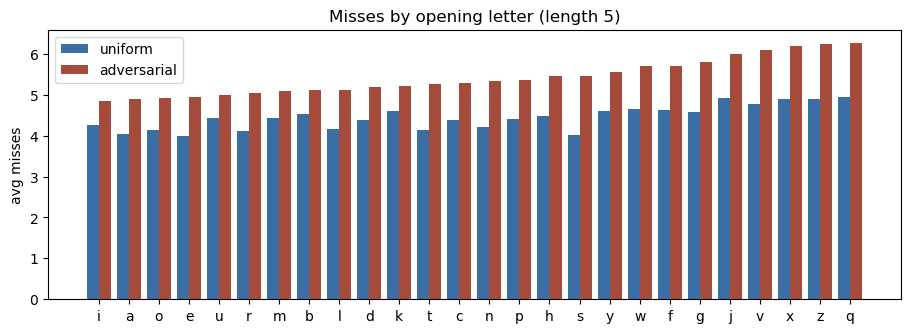

,i,a,o,e,u,r,m,b,l,d,...,s,y,w,f,g,j,v,x,z,q
uniform,4.249499,4.032904,4.147639,3.998856,4.440343,4.10701,4.437768,4.528469,4.151931,4.374249,...,4.015737,4.610873,4.656938,4.630329,4.567382,4.917883,4.771388,4.906152,4.906152,4.955079
adversarial,4.850188,4.905611,4.927435,4.939516,4.984933,5.04602,5.078783,5.108691,5.115382,5.178020,...,5.465610,5.551929,5.691294,5.691297,5.792653,5.997991,6.087305,6.180020,6.233408,6.272976


In [86]:
# avg misses + opening letter, each version
for name, fr in [('uniform', None), ('adversarial', f)]:
    print(f'{name:>12}:  avg misses {game.average_misses(fr):.4f}   '
          f'opener {game.greedy_first_letter(fr)!r}')

# Mode B -- expected misses by opening letter, both versions side by side
mb = pd.DataFrame({
    'uniform':     pd.Series(game.misses_by_starting_letter(None)),
    'adversarial': pd.Series(game.misses_by_starting_letter(f)),
}).sort_values('adversarial')

x = np.arange(len(mb)); w = 0.4
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(x - w / 2, mb['uniform'],     w, label='uniform',     color='#3b6ea5')
ax.bar(x + w / 2, mb['adversarial'], w, label='adversarial', color='#a54b3b')
ax.set_xticks(x); ax.set_xticklabels(mb.index)
ax.set_ylabel('avg misses'); ax.legend()
ax.set_title(f'Misses by opening letter (length {LENGTH})')
plt.show()
mb.T

## Per-word difficulty (both versions)

In [ ]:
pwm_u = game.per_word_misses(None)      # uniform
pwm_a = game.per_word_misses(f)         # adversarial
words = pd.DataFrame({'word': game.words, 'freq': f,
                      'misses_uniform':     pwm_u.astype(int),
                      'misses_adversarial': pwm_a.astype(int)})

print(f'weighted avg misses -- uniform {game.average_misses(None):.4f}   '
      f'adversarial {game.average_misses(f):.4f}')

# frequency-weighted: each word contributes its frequency (uniform -> 1 each,
# adversarial -> f), normalized to a share of total weight so the two curves are
# comparable and consistent with the weighted averages above.
bins = range(0, int(max(pwm_u.max(), pwm_a.max())) + 2)
fig, ax = plt.subplots(figsize=(9, 3))
for pwm, wt, name, color in [(pwm_u, None, 'uniform',     '#3b6ea5'),
                             (pwm_a, f,    'adversarial', '#a54b3b')]:
    ax.hist(pwm, bins=bins, weights=wt, density=True,
            alpha=0.6, label=name, color=color, align='left')
ax.set_xlabel('misses'); ax.set_ylabel('share of frequency'); ax.legend()
plt.show()

print('hardest words under the adversarial distribution:')
words.sort_values('misses_adversarial', ascending=False).head(15).reset_index(drop=True)

In [88]:
# The adversary zeros out many words (freq 0) -- those don't count toward its
# average. Hardest words it actually KEEPS (nonzero adversarial frequency):
kept = words[words.freq > 0]
print(f'{len(kept)} of {len(words)} words kept (nonzero frequency)')
kept.sort_values('misses_adversarial', ascending=False).head(15).reset_index(drop=True)

2076 of 3495 words kept (nonzero frequency)


,word,freq,misses_uniform,misses_adversarial
0,mommy,1.7500,10,12
1,wonky,1.7500,7,12
2,haves,1.3750,6,12
3,wally,3.5000,10,12
4,hammy,3.5000,6,12
5,paves,1.3750,7,12
6,wound,4.0000,10,12
7,mammy,1.7500,6,12
8,wacky,3.5000,9,11
9,faves,1.3750,5,11


## Trace a word (both versions)

The greedy guess sequence for one word under each weighting (`+` = hit, `-` = miss).
The two can differ because the adversarial weighting changes which letters greedy
guesses first.

In [89]:
# hardest word the adversary actually KEEPS (nonzero frequency); or set WORD = 'bench'
nz = np.flatnonzero(f > 0)
WORD = game.words[nz[pwm_a[nz].argmax()]]
print(WORD)
for name, fr in [('uniform', None), ('adversarial', f)]:
    hits = game.trace(WORD, fr)
    seq = '  '.join(f'{l}{"+" if h else "-"}' for l, h in hits)
    print(f'{name:>12}  ({sum(1 for _, h in hits if not h)} misses):  {seq}')

wound
     uniform  (10 misses):  e-  s-  a-  o+  y-  u+  d+  n+  b-  f-  h-  m-  p-  r-
 adversarial  (12 misses):  s-  y-  e-  c-  i-  u+  l-  n+  d+  o+  b-  f-  h-  m-  p-  r-
